<a href="https://colab.research.google.com/github/KangKyungHwa/DSMH_2/blob/main/_10_8/%EC%84%A0%ED%98%95%ED%9A%8C%EA%B7%80%EB%AA%A8%EB%8D%B8_%EC%97%B0%EC%8A%B5(1)_(10%EC%9B%948%EC%9D%BC).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 통계 회귀 모델 실습(4)
## Simple Linear Regression (단순선형회귀분석) : 독립변수 1, 종속변수1 개



## Multiple Linear Regression (다중선형회귀분석) : 독립변수 여러개(2개이상), 종속변수1 개

1. 가설 설정

2. 데이터 수집 및 전처리

* (1) 데이터 수집

In [ ]:
!git clone 'https://'github.com/KangKyungHwa/DSMH_2/''

# 1. 나눔고딕 폰트 설치
!sudo apt-get update -qq
!sudo apt-get install -y fonts-nanum-extra -qq

# 2. 시스템 폰트 캐시 업데이트
!sudo fc-cache -fv

# 3. Matplotlib 폰트 캐시 삭제
!rm -rf ~/.cache/matplotlib

from matplotlib import pyplot as plt

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['font.size'] = 11

fatal: destination path 'DSMH_2' already exists and is not an empty directory.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu/dists/noble/InRelease  503  Service Unavailable [IP: 185.125.189.188 443]
W: Some index files failed to download. They have been ignored, or old ones used instead.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3

In [ ]:
from os import setns
import pandas as pd # 데이터 로드 및 전처리에 사용
import numpy as np
import statsmodels.formula.api as smf # 통계적 회귀 모델 생성 및 분석에 사용
import seaborn as sns
import matplotlib.pyplot as plt


advertising = pd.read_csv("DSMH_2/_10_8/Advertising.csv")

print(advertising.head(3), '\n\n')
print(advertising.tail(3))

   Unnamed: 0     TV  radio  newspaper  sales
0           1  230.1   37.8       69.2   22.1
1           2   44.5   39.3       45.1   10.4
2           3   17.2   45.9       69.3    9.3 


     Unnamed: 0     TV  radio  newspaper  sales
197         198  177.0    9.3        6.4   12.8
198         199  283.6   42.0       66.2   25.5
199         200  232.1    8.6        8.7   13.4


In [ ]:
print (advertising.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB
None


* (2) seaborn 라이브러리를 이용하여 산점도 그려보기

<Axes: xlabel='TV', ylabel='sales'>

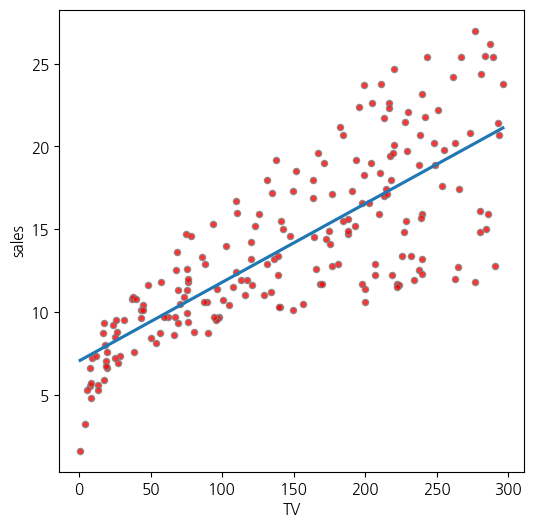

In [ ]:
plt.rcParams['figure.figsize'] = (6, 6)
sns.regplot(x='TV', y='sales', data=advertising,
            order=1, ci=None, scatter_kws={'color':'r','s':20,
            'edgecolor':'gray'})

3. 모델 생성 및 학습 : 선형회귀분석 핵심 코드

In [ ]:
# 선형 회귀 모델 생성
import statsmodels.formula.api as smf

model = smf.ols('sales~TV', data = advertising)   # 회귀분석 : "~"표시는 예측한다는 의미
olsfit = model.fit()   #데이터에 적용하기
print(olsfit.summary())


                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.612
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     312.1
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           1.47e-42
Time:                        14:34:59   Log-Likelihood:                -519.05
No. Observations:                 200   AIC:                             1042.
Df Residuals:                     198   BIC:                             1049.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.0326      0.458     15.360      0.0

#### TV광고에 1단위(1000달러)를 지출하면 제품판매량이 0.0475 증가한다는 의미 (0.0475x1000=47.5개 판매증가 예측됨)
#### R-squared (R제곱값) 이 1에 가까울수록 Y변동의 상당부분이 회귀에 의해 설명되었다는 의미; Y의 변동 중 61.2% 가 회귀선에 의해 설명됨

## Multiple Linear Regression (다중선형회귀분석) : 독립변수 여러개(2개이상), 종속변수1 개

In [ ]:
#  다중 회귀 모델 생성
lm_fit = smf.ols("sales ~TV+radio+newspaper", data = advertising).fit()
print(lm_fit.summary())


                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           1.58e-96
Time:                        14:35:15   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.0

### 4. TV와 라디오 광고의 매출 기여도 시각화

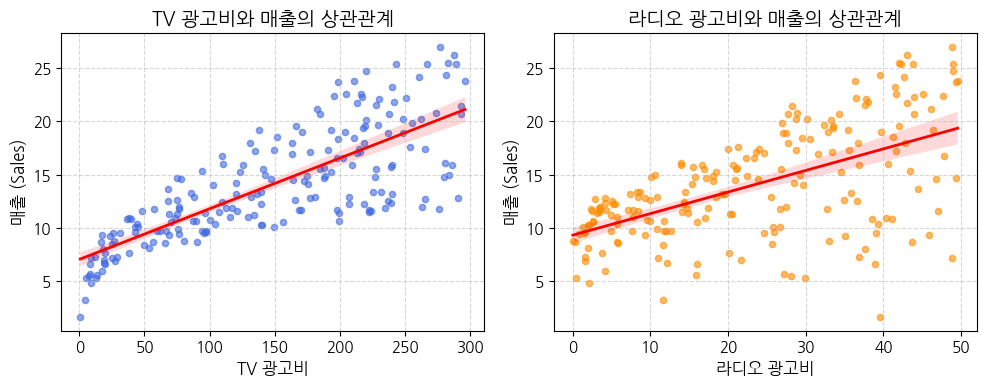

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. TV와 라디오의 개별 상관관계 시각화 (서브플롯)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.regplot(x='TV', y='sales', data=advertising, ax=axes[0],
            scatter_kws={'color':'royalblue', 'alpha':0.6, 's':20},
            line_kws={'color':'red', 'linewidth':2})
axes[0].set_title('TV 광고비와 매출의 상관관계', fontsize=14)
axes[0].set_xlabel('TV 광고비', fontsize=12)
axes[0].set_ylabel('매출 (Sales)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

sns.regplot(x='radio', y='sales', data=advertising, ax=axes[1],
            scatter_kws={'color':'darkorange', 'alpha':0.6, 's':20},
            line_kws={'color':'red', 'linewidth':2})
axes[1].set_title('라디오 광고비와 매출의 상관관계', fontsize=14)
axes[1].set_xlabel('라디오 광고비', fontsize=12)
axes[1].set_ylabel('매출 (Sales)', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

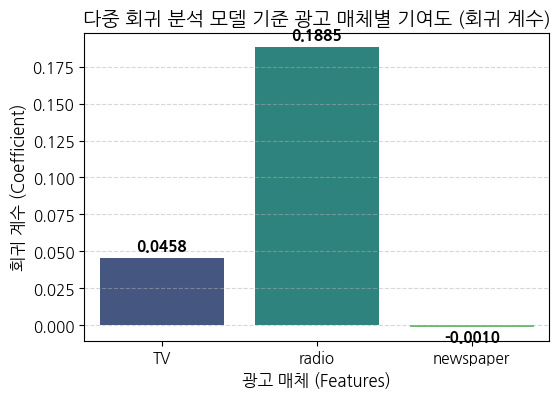

In [ ]:
# 2. 다중회귀모델(lm_fit)에서 추출한 변수별 영향력(회귀 계수) 비교
coef_series = lm_fit.params.drop('Intercept')  # 절편을 제외한 광고 변수들 추출

plt.figure(figsize=(6, 4))
sns.barplot(x=coef_series.index, y=coef_series.values, palette='viridis', hue=coef_series.index, legend=False)
plt.title('다중 회귀 분석 모델 기준 광고 매체별 기여도 (회귀 계수)', fontsize=14)
plt.xlabel('광고 매체 (Features)', fontsize=12)
plt.ylabel('회귀 계수 (Coefficient)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 각 막대 위에 수치 표시
for idx, value in enumerate(coef_series.values):
    plt.text(idx, value + (0.005 if value >= 0 else -0.01), f"{value:.4f}", ha='center', fontsize=11, fontweight='bold')

plt.show()